<a href="https://colab.research.google.com/github/Vikuska31/Avito.Antibot/blob/main/Lab4_1_MNIST_GNN_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ЛР 4-1. Классификация MNIST на основе графовой нейросети (GATv2)

**Постановка задачи.** Изображения цифр MNIST преобразуются в графовые представления (суперпиксели SLIC + граф смежности областей RAG) и классифицируются графовой нейросетью на слоях `GATv2Conv`.
С целью сбережения ресурсов используются только тестовые данные MNIST (10 000 изображений), которые делятся на обучающие (80 %) и проверочные (20 %).

**Порядок выполнения:**
1. Загрузка тестовых данных MNIST.
2. Преобразование изображений в графовые представления (суперпиксели).
3. Визуализация примеров графовых представлений – по одному в каждом классе.
4. Создание модели на основе `GATv2Conv`, обучение, сохранение весов в файл, тестирование (веса загружаются из файла).
5. Сравнение результатов при 50, 75 и 100 узлах и сравнение `global_mean_pool` с `global_max_pool`.
6. Визуализация весов внимания (факультативно).

### Блок 1. Установка библиотек

Ячейка нужна только при первом запуске (например, в Colab): устанавливает `torch_geometric` (слои GNN и загрузчик графовых данных) и `scikit-image` (алгоритм SLIC и построение RAG). Если библиотеки уже установлены, ячейку можно пропустить.

In [1]:
# при необходимости установить:
!pip install torch_geometric scikit-image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 31.1 MB/s eta 0:00:00


### Блок 2. Импорт библиотек и выбор устройства

Импортируются:
- `torchvision.datasets.MNIST` – загрузка данных;
- `slic` и `rag_mean_color` из `skimage` – сегментация изображения на суперпиксели и построение графа смежности областей;
- `Data`, `DataLoader`, `to_networkx` из `torch_geometric` – контейнер графа, пакетная загрузка графов и конвертация в `networkx` для отрисовки;
- `GATv2Conv`, `BatchNorm`, `global_mean_pool`, `global_max_pool`, `summary` – слои модели и вывод её структуры;
- `classification_report`, `accuracy_score` из `sklearn` – метрики качества.

В переменную `device` записывается GPU, если он доступен, иначе CPU.

In [2]:
import time
import numpy as np
import torch
import torch.nn.functional as F
import networkx as nx
import matplotlib.pyplot as plt

from torchvision.datasets import MNIST
from skimage.segmentation import slic
from skimage.graph import rag_mean_color
from sklearn.metrics import classification_report, accuracy_score

from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.utils import to_networkx
from torch_geometric.nn import GATv2Conv, BatchNorm, global_mean_pool, global_max_pool, summary

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


## 1. Загрузка тестовых данных MNIST и разбиение 80 % / 20 %

### Блок 3. Загрузка данных и формирование выборок

Загружается **только тестовая** часть MNIST (`train=False`) – 10 000 изображений 28×28. Значения пикселей делятся на 255, то есть приводятся к диапазону 0…1 (так же, как в коде из задания). Метки `y_all` – цифры 0…9.

Индексы изображений перемешиваются генератором со **фиксированным зерном** `0` (чтобы разбиение повторялось при каждом запуске) и делятся в отношении 80 / 20: 8 000 изображений на обучение и 2 000 на проверку.

In [3]:
mnist = MNIST(root='./mnist', train=False, download=True)
x_all = mnist.data.numpy() / 255        # (10000, 28, 28), значения 0..1
y_all = mnist.targets.numpy()           # (10000,), цифры 0..9
print('Изображения:', x_all.shape, 'Метки:', y_all.shape)

# Разбиение на обучающую (80%) и проверочную (20%) части
rng = np.random.default_rng(0)
idx = rng.permutation(len(x_all))
n_trn = int(0.8 * len(idx))
idx_trn, idx_tst = idx[:n_trn], idx[n_trn:]
print('Обучающих:', len(idx_trn), 'Проверочных:', len(idx_tst))

100%|██████████| 9.91M/9.91M [00:00<00:00, 125MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 15.7MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 88.8MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.34MB/s]


Изображения: (10000, 28, 28) Метки: (10000,)
Обучающих: 8000 Проверочных: 2000


## 2. Преобразование изображений в графовые представления (суперпиксели)

### Блок 4. Функция `image_to_superpixel_graph`

Функция превращает одно изображение 28×28 в объект `Data` библиотеки PyG. Шаги:

1. **Сегментация SLIC.** Изображение дублируется по трём каналам (SLIC ожидает цветное изображение) и разбивается на `n_segments` суперпикселей. `compactness=1` – слабое требование к компактности областей, то есть границы сегментов подстраиваются под яркость (под штрих цифры). `start_label=1` – нумерация сегментов с единицы.
2. **Построение RAG.** `rag_mean_color` строит граф смежности областей: два сегмента соединяются ребром, если они соприкасаются на изображении.
3. **Признаки узлов.** Для каждого сегмента вычисляются средняя интенсивность и координаты центра масс (центроида). Координаты делятся на высоту и ширину изображения, то есть нормируются к диапазону 0…1 – иначе координаты (0…27) доминировали бы над яркостью (0…1). Итого **3 признака на узел**: `[средняя яркость, y/h, x/w]`.
4. **Рёбра.** Каждое ребро RAG записывается в `edge_index` **дважды** – в обе стороны, так как в PyG рёбра направленные, а соседство суперпикселей взаимно. Из номеров узлов вычитается 1, чтобы индексы начинались с нуля.
5. **Метка.** `y` – цифра, изображённая на картинке (метка всего графа, а не отдельных узлов).

Дополнительно в `pos` сохраняются ненормированные координаты центроидов – они нужны только для отрисовки графа.

In [4]:
def image_to_superpixel_graph(img, lb, n_segments=75):
    h, w = img.shape[:2]
    # 1. Сегментация: разбиваем 28x28 на n суперпикселей (img должен быть 3D для SLIC)
    if len(img.shape) == 2:
        img = np.stack([img] * 3, axis=-1)
    labels = slic(img, n_segments=n_segments, compactness=1, start_label=1)

    # 2. Построение RAG (Region Adjacency Graph) - поиск соседних сегментов
    rag = rag_mean_color(img, labels)

    # 3. Признаки узлов: средняя яркость + нормированные координаты центроида
    node_features, node_pos, edge_indices = [], [], []
    for node in rag.nodes:
        mask = (labels == node)
        mean_intensity = img[mask].mean()
        coords = np.argwhere(mask)
        n_pos = coords.mean(axis=0)                       # [y, x]
        normalized_pos = [n_pos[0] / h, n_pos[1] / w]
        node_features.append([mean_intensity, normalized_pos[0], normalized_pos[1]])
        node_pos.append(n_pos)

    x = torch.tensor(node_features, dtype=torch.float)
    pos = torch.tensor(np.array(node_pos), dtype=torch.float)

    # 4. Рёбра (соседство сегментов), двунаправленные; в rag узлы нумеруются с 1
    for u, v in rag.edges:
        edge_indices.append([u - 1, v - 1])
        edge_indices.append([v - 1, u - 1])
    edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()

    # 5. y - метка класса
    y = torch.tensor([lb], dtype=torch.long)
    return Data(x=x, y=y, edge_index=edge_index, pos=pos)

### Блок 5. Проверка преобразования на одном изображении

Строится граф для первого изображения выборки и выводятся его характеристики: число узлов (оно обычно **меньше** заданного `n_segments`, так как SLIC объединяет однородные области фона), число рёбер (каждая связь учтена дважды) и форма матрицы признаков `[число_узлов, 3]`.

In [5]:
sp_graph = image_to_superpixel_graph(x_all[0], y_all[0], n_segments=75)
print('Граф создан:')
print('- Узлов:', sp_graph.num_nodes)
print('- Рёбер:', sp_graph.num_edges, '(связи между соседями)')
print('- Размер признаков:', tuple(sp_graph.x.shape))

Граф создан:
- Узлов: 62
- Рёбер: 346 (связи между соседями)
- Размер признаков: (62, 3)


## 3. Визуализация графовых представлений – по одному примеру в каждом классе

### Блок 6. Функция отрисовки графа

Граф PyG конвертируется в неориентированный граф `networkx`. Координаты узлов берутся из `data.pos`: по горизонтали откладывается `-x`, по вертикали `y` – такой разворот даёт изображение цифры в привычной ориентации. Цвет узла кодирует среднюю яркость суперпикселя (пастельная сине-голубая палитра `PuBu`), серые линии – рёбра графа.

In [6]:
def visualize_graph(data, with_cb=1, nd_size=150):
    G = to_networkx(data, to_undirected=True)
    pos = {i: (-data.pos[i][1].item(), data.pos[i][0].item()) for i in range(data.num_nodes)}
    node_color = data.x[:, 0].tolist()
    nx.draw_networkx_edges(G, pos, alpha=0.3, edge_color='gray')
    nodes = nx.draw_networkx_nodes(G, pos, node_size=nd_size,
                                   node_color=node_color, cmap=plt.cm.PuBu)
    if with_cb:
        plt.colorbar(nodes, label='Интенсивность суперпикселя')
    plt.title(f'Цифра: {data.y.item()}')
    plt.axis('off')

### Блок 7. Примеры графов для всех десяти классов

Для каждой цифры 0…9 берётся первое встретившееся в выборке изображение, строится его граф (75 суперпикселей) и выводится на общий рисунок 2×5. Видно, что яркие узлы выстраиваются вдоль штриха цифры, а фон образует крупные тёмные сегменты.

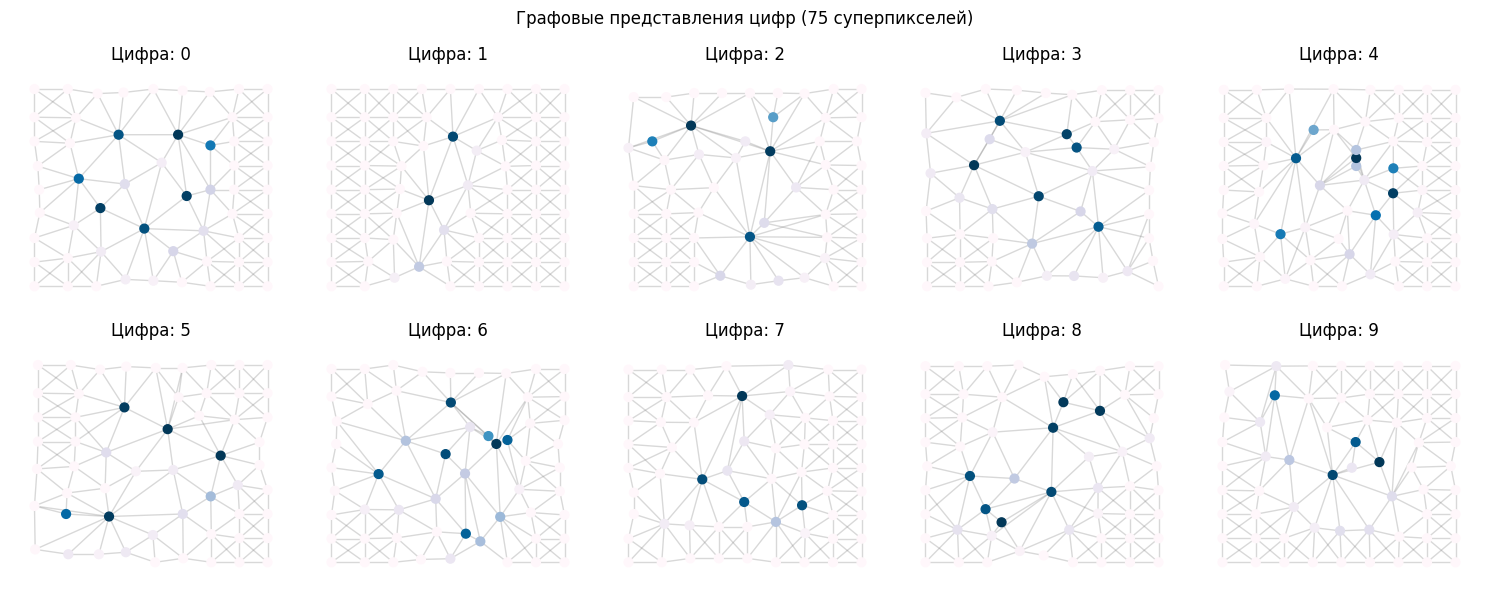

In [7]:
plt.figure(figsize=(15, 6))
for digit in range(10):
    i = np.where(y_all == digit)[0][0]          # первый пример данного класса
    g = image_to_superpixel_graph(x_all[i], y_all[i], n_segments=75)
    plt.subplot(2, 5, digit + 1)
    visualize_graph(g, with_cb=0, nd_size=40)
plt.suptitle('Графовые представления цифр (75 суперпикселей)')
plt.tight_layout()
plt.show()

## 4. Модель нейросети на основе GATv2Conv

### Блок 8. Класс `GATClassifier`

Архитектура сети:

| Слой | Назначение |
|---|---|
| `GATv2Conv(3 → 64, heads=4)` | первый шаг передачи сообщений; 4 головы внимания дают 4 независимых набора весов связей, их выходы конкатенируются → 256 признаков |
| `BatchNorm(256)` + `ReLU` | нормировка признаков узлов по пакету, стабилизирует и ускоряет обучение |
| `GATv2Conv(256 → 64, heads=4)` | второй шаг передачи сообщений, узел «видит» соседей на расстоянии двух рёбер |
| `BatchNorm(256)` + `ReLU` | то же для второго слоя |
| `pool` (`global_mean_pool` / `global_max_pool`) | readout: схлопывает граф произвольного размера в один вектор длины 256 |
| `Dropout(0.4)` | регуляризация перед классификатором |
| `Linear(256 → 10)` + `log_softmax` | классификация на 10 цифр |

Функция объединения вынесена в параметр `pool`, чтобы одним и тем же классом провести оба эксперимента – со средним и с максимумом.

In [8]:
class GATClassifier(torch.nn.Module):
    def __init__(self, hidden_channels=64, heads=4, pool=global_mean_pool):
        super(GATClassifier, self).__init__()
        # heads=4: сеть смотрит на граф 4 разными "взглядами",
        # выходы голов конкатенируются -> hidden_channels * heads
        self.conv1 = GATv2Conv(3, hidden_channels, heads=heads)
        self.bn1 = BatchNorm(hidden_channels * heads)
        self.conv2 = GATv2Conv(hidden_channels * heads, hidden_channels, heads=heads)
        self.bn2 = BatchNorm(hidden_channels * heads)
        self.lin = torch.nn.Linear(hidden_channels * heads, 10)
        self.pool = pool

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        # Слой 1
        x = self.conv1(x, edge_index)
        x = self.bn1(x).relu()
        # Слой 2
        x = self.conv2(x, edge_index)
        x = self.bn2(x).relu()
        # Глобальное объединение
        x = self.pool(x, batch)
        x = F.dropout(x, p=0.4, training=self.training)
        x = self.lin(x)
        return F.log_softmax(x, dim=1)

### Блок 9. Summary модели

Функция `summary` из `torch_geometric` прогоняет через модель один граф и выводит таблицу слоёв: форму входа, форму выхода и число обучаемых параметров. Таблица включается в отчёт.

In [9]:
model = GATClassifier()
print('Форма входа:', tuple(sp_graph.x.shape))
print(summary(model, sp_graph))

Форма входа: (62, 3)
+----------------------------+---------------------+----------------+----------+
| Layer                      | Input Shape         | Output Shape   | #Param   |
|----------------------------+---------------------+----------------+----------|
| GATClassifier              | [62, 62]            | [1, 10]        | 138,250  |
| ├─(conv1)GATv2Conv         | [62, 3], [2, 346]   | [62, 256]      | 2,560    |
| ├─(bn1)BatchNorm           | [62, 256]           | [62, 256]      | 512      |
| │    └─(module)BatchNorm1d | [62, 256]           | [62, 256]      | 512      |
| ├─(conv2)GATv2Conv         | [62, 256], [2, 346] | [62, 256]      | 132,096  |
| ├─(bn2)BatchNorm           | [62, 256]           | [62, 256]      | 512      |
| │    └─(module)BatchNorm1d | [62, 256]           | [62, 256]      | 512      |
| ├─(lin)Linear              | [1, 256]            | [1, 10]        | 2,570    |
+----------------------------+---------------------+----------------+----------+


## 5. Обучение, сохранение весов, тестирование

### Блок 10. Функция `run_experiment`

Выполняет полный цикл одного эксперимента для заданного числа суперпикселей и заданной функции глобального объединения:

1. строит графовые представления для обучающей и проверочной выборок, замеряет время и среднее число узлов и рёбер;
2. оборачивает списки графов в `DataLoader` (он объединяет графы в пакеты и формирует вектор `batch`, указывающий, какому графу принадлежит каждый узел);
3. обучает модель `n_ep` эпох: оптимизатор `Adam` (`lr=0.001`, `weight_decay=1e-4`), функция потерь `CrossEntropyLoss`, планировщик `ReduceLROnPlateau` уменьшает шаг обучения вдвое, если точность на проверке перестаёт расти;
4. после каждой эпохи выводит потери и точность на проверочной выборке;
5. **сохраняет веса модели в файл** `<name>.pt`;
6. **создаёт модель заново и загружает веса из файла** – тестирование проводится именно загруженной моделью, как требует задание;
7. возвращает словарь с метриками, предсказаниями, самой моделью и проверочной выборкой (модель и выборка понадобятся для визуализации внимания).

In [10]:
n_ep = 10
lr, wd = 0.001, 1e-4      # для Adam
factor = 0.5              # для ReduceLROnPlateau
batch_size = 64

def run_experiment(name, n_segments, pool):
    print(f'=== {name}: n_segments={n_segments}, pool={pool.__name__} ===')

    # Построение графовых представлений
    t0 = time.time()
    trn_set = [image_to_superpixel_graph(x_all[i], y_all[i], n_segments) for i in idx_trn]
    tst_set = [image_to_superpixel_graph(x_all[i], y_all[i], n_segments) for i in idx_tst]
    t_graphs = time.time() - t0
    avg_nodes = np.mean([g.num_nodes for g in trn_set])
    avg_edges = np.mean([g.num_edges for g in trn_set])
    print(f'Графы построены за {t_graphs:.1f} c; узлов в среднем: {avg_nodes:.1f}, рёбер: {avg_edges:.1f}')

    trn_loader = DataLoader(trn_set, batch_size=batch_size, shuffle=True)
    tst_loader = DataLoader(tst_set, batch_size=batch_size)

    # Обучение
    model = GATClassifier(pool=pool).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max',
                                                           factor=factor, patience=5)
    criterion = torch.nn.CrossEntropyLoss()

    print('Обучение')
    t0 = time.time()
    for epoch in range(n_ep):
        model.train()
        total_loss = 0
        for data in trn_loader:
            data = data.to(device)
            optimizer.zero_grad()
            out = model(data)
            loss = criterion(out, data.y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * data.num_graphs
        loss = total_loss / len(trn_set)

        model.eval()
        correct = 0
        with torch.no_grad():
            for data in tst_loader:
                data = data.to(device)
                correct += int((model(data).argmax(dim=1) == data.y).sum())
        acc = correct / len(tst_set)
        scheduler.step(acc)
        print(f'Эпоха: {epoch:02d}, Потери: {loss:.4f}, Точность на тесте: {acc:.4f}')
    t_train = time.time() - t0

    # Сохранение весов модели в файл
    torch.save(model.state_dict(), f'{name}.pt')

    # Тестирование: веса загружаются из файла
    model = GATClassifier(pool=pool).to(device)
    model.load_state_dict(torch.load(f'{name}.pt'))
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for data in tst_loader:
            data = data.to(device)
            y_pred += model(data).argmax(dim=1).cpu().tolist()
            y_true += data.y.cpu().tolist()
    acc = accuracy_score(y_true, y_pred)
    print(f'Точность загруженной из файла модели: {acc:.4f}\n')

    return {'name': name, 'n_segments': n_segments, 'pool': pool.__name__,
            'nodes': avg_nodes, 'edges': avg_edges, 't_graphs': t_graphs,
            't_train': t_train, 'acc': acc, 'y_true': y_true, 'y_pred': y_pred,
            'model': model, 'tst_set': tst_set}

### Блок 11. Запуск четырёх экспериментов

Три эксперимента с `global_mean_pool` и разным числом суперпикселей (50, 75, 100) – для первой таблицы отчёта, и четвёртый эксперимент с `global_max_pool` при 75 узлах – для второй таблицы. Веса каждой модели сохраняются в отдельный файл.

Запуск занимает заметное время: построение 10 000 графов повторяется для каждого эксперимента.

In [11]:
res_50 = run_experiment('gat_n50', 50, global_mean_pool)
res_75 = run_experiment('gat_n75', 75, global_mean_pool)
res_100 = run_experiment('gat_n100', 100, global_mean_pool)
res_75_max = run_experiment('gat_n75_max', 75, global_max_pool)

=== gat_n50: n_segments=50, pool=global_mean_pool ===
Графы построены за 123.2 c; узлов в среднем: 33.7, рёбер: 160.6
Обучение
Эпоха: 00, Потери: 1.8742, Точность на тесте: 0.2645
Эпоха: 01, Потери: 1.4983, Точность на тесте: 0.3740
Эпоха: 02, Потери: 1.3036, Точность на тесте: 0.5425
Эпоха: 03, Потери: 1.1774, Точность на тесте: 0.6225
Эпоха: 04, Потери: 1.0569, Точность на тесте: 0.6700
Эпоха: 05, Потери: 0.9754, Точность на тесте: 0.6540
Эпоха: 06, Потери: 0.9049, Точность на тесте: 0.7470
Эпоха: 07, Потери: 0.8506, Точность на тесте: 0.7160
Эпоха: 08, Потери: 0.8177, Точность на тесте: 0.7580
Эпоха: 09, Потери: 0.7745, Точность на тесте: 0.7785
Точность загруженной из файла модели: 0.7785

=== gat_n75: n_segments=75, pool=global_mean_pool ===
Графы построены за 135.3 c; узлов в среднем: 58.9, рёбер: 326.6
Обучение
Эпоха: 00, Потери: 1.8649, Точность на тесте: 0.4400
Эпоха: 01, Потери: 1.4912, Точность на тесте: 0.5200
Эпоха: 02, Потери: 1.2815, Точность на тесте: 0.5290
Эпоха: 03, 

### Блок 12. Classification report базовой модели

Отчёт по классификации для основной конфигурации (75 суперпикселей, `global_mean_pool`): для каждой цифры выводятся точность (precision), полнота (recall), F-мера и число примеров в проверочной выборке, а также усреднённые показатели.

In [12]:
print(classification_report(res_75['y_true'], res_75['y_pred'], digits=4))

              precision    recall  f1-score   support

           0     0.9171    0.8646    0.8901       192
           1     0.8229    0.9738    0.8920       229
           2     0.9080    0.7215    0.8041       219
           3     0.8146    0.7952    0.8048       210
           4     0.7871    0.6971    0.7394       175
           5     0.8182    0.7459    0.7803       181
           6     0.8824    0.7820    0.8291       211
           7     0.9551    0.7340    0.8301       203
           8     0.6875    0.8934    0.7770       197
           9     0.6720    0.9180    0.7760       183

    accuracy                         0.8145      2000
   macro avg     0.8265    0.8125    0.8123      2000
weighted avg     0.8294    0.8145    0.8147      2000



### Блок 13. Таблица 1 – сравнение при разном числе узлов

Сводная таблица по трём экспериментам: заданное число сегментов, фактическое среднее число узлов и рёбер в графе, время построения графов, время обучения и итоговая точность. Таблица показывает компромисс между детализацией графа и вычислительными затратами.

In [13]:
print(f"{'n_segments':>11} | {'узлов':>7} | {'рёбер':>7} | {'t графов, c':>12} | {'t обуч., c':>11} | {'accuracy':>9}")
print('-' * 72)
for r in [res_50, res_75, res_100]:
    print(f"{r['n_segments']:>11} | {r['nodes']:>7.1f} | {r['edges']:>7.1f} | "
          f"{r['t_graphs']:>12.1f} | {r['t_train']:>11.1f} | {r['acc']:>9.4f}")

 n_segments |   узлов |   рёбер |  t графов, c |  t обуч., c |  accuracy
------------------------------------------------------------------------
         50 |    33.7 |   160.6 |        123.2 |       320.7 |    0.7785
         75 |    58.9 |   326.6 |        135.3 |       601.7 |    0.8145
        100 |    58.9 |   326.6 |        133.7 |       619.6 |    0.8135


### Блок 14. Classification report для 50 и 100 узлов

Подробные отчёты по оставшимся двум конфигурациям – позволяют увидеть, на каких именно цифрах теряется или выигрывается качество при изменении детализации графа.

In [14]:
for r in [res_50, res_100]:
    print(f"--- n_segments = {r['n_segments']} ---")
    print(classification_report(r['y_true'], r['y_pred'], digits=4))

--- n_segments = 50 ---
              precision    recall  f1-score   support

           0     0.7625    0.9531    0.8472       192
           1     0.9820    0.9520    0.9667       229
           2     0.8443    0.6438    0.7306       219
           3     0.6442    0.8190    0.7212       210
           4     0.7660    0.6171    0.6835       175
           5     0.7500    0.6630    0.7038       181
           6     0.9066    0.7820    0.8397       211
           7     0.8370    0.7586    0.7959       203
           8     0.7245    0.7208    0.7226       197
           9     0.6390    0.8415    0.7264       183

    accuracy                         0.7785      2000
   macro avg     0.7856    0.7751    0.7738      2000
weighted avg     0.7911    0.7785    0.7783      2000

--- n_segments = 100 ---
              precision    recall  f1-score   support

           0     0.9667    0.7552    0.8480       192
           1     0.9777    0.9563    0.9669       229
           2     0.7917    0.

### Блок 15. Таблица 2 – `global_mean_pool` против `global_max_pool`

Сравнение двух функций глобального объединения при одинаковом числе узлов (75) и прочих равных условиях, плюс подробный отчёт по классификации для варианта с максимумом.

In [15]:
print(f"{'pool':>17} | {'accuracy':>9}")
print('-' * 29)
for r in [res_75, res_75_max]:
    print(f"{r['pool']:>17} | {r['acc']:>9.4f}")
print()
print('--- global_max_pool ---')
print(classification_report(res_75_max['y_true'], res_75_max['y_pred'], digits=4))

             pool |  accuracy
-----------------------------
 global_mean_pool |    0.8145
  global_max_pool |    0.7815

--- global_max_pool ---
              precision    recall  f1-score   support

           0     0.7952    0.8698    0.8308       192
           1     0.9644    0.9476    0.9559       229
           2     0.8500    0.7763    0.8115       219
           3     0.8039    0.7810    0.7923       210
           4     0.7817    0.6343    0.7003       175
           5     0.5890    0.7127    0.6450       181
           6     0.7882    0.7583    0.7729       211
           7     0.8605    0.7291    0.7893       203
           8     0.7978    0.7411    0.7684       197
           9     0.6240    0.8251    0.7106       183

    accuracy                         0.7815      2000
   macro avg     0.7855    0.7775    0.7777      2000
weighted avg     0.7921    0.7815    0.7833      2000



## 6. Визуализация внимания (Attention) – факультативно

### Блок 16. Веса внимания первого слоя

Первый слой обученной модели вызывается напрямую с аргументом `return_attention_weights=True` – он возвращает не только новые признаки узлов, но и пару `(edge_index_attn, alpha)`. Веса усредняются по четырём головам внимания.

Важная деталь: `edge_index_attn` **длиннее** исходного `edge_index`, потому что слой `GATv2Conv` автоматически добавляет петли (self-loops) – каждый узел учитывает и сам себя. Петли при отрисовке отбрасываются.

На рисунке толщина и цвет ребра (пастельная розовая палитра `RdPu`) пропорциональны весу внимания: наибольшие веса приходятся на связи вдоль штриха цифры и на её изгибах, фоновые связи получают почти нулевой вес.

Исходный edge_index: (2, 292)
edge_index_attn: (2, 346) (добавлены петли)


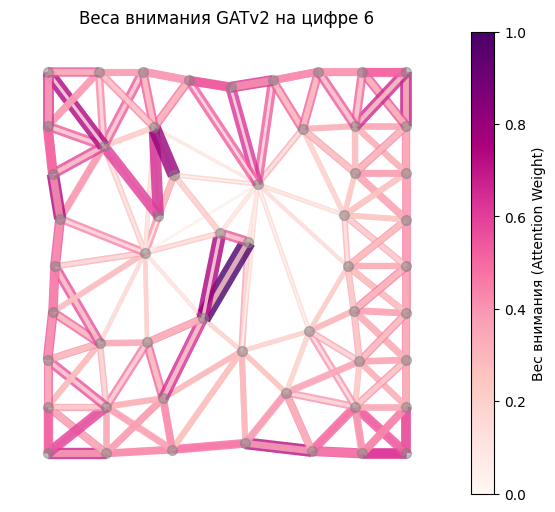

In [16]:
model = res_75['model']
g = res_75['tst_set'][0].to(device)

model.eval()
with torch.no_grad():
    x_out, (edge_index_attn, alpha) = model.conv1(g.x, g.edge_index, return_attention_weights=True)
alpha_mean = alpha.mean(dim=1)          # усредняем по головам внимания
print('Исходный edge_index:', tuple(g.edge_index.shape))
print('edge_index_attn:', tuple(edge_index_attn.shape), '(добавлены петли)')

pos = {i: (-g.pos[i][1].item(), g.pos[i][0].item()) for i in range(g.num_nodes)}
edges, weights = [], []
for i in range(edge_index_attn.shape[1]):
    u, v = edge_index_attn[0, i].item(), edge_index_attn[1, i].item()
    if u != v:                           # петли не рисуем
        edges.append((u, v))
        weights.append(alpha_mean[i].item())

G = nx.DiGraph()
G.add_nodes_from(range(g.num_nodes))
plt.figure(figsize=(7, 6))
plt.title(f'Веса внимания GATv2 на цифре {g.y.item()}')
nx.draw_networkx_nodes(G, pos, node_size=50, node_color='gray', alpha=0.5)
edges_plot = nx.draw_networkx_edges(G, pos, edgelist=edges, edge_color=weights,
                                    edge_cmap=plt.cm.RdPu,
                                    width=[w * 30 for w in weights],
                                    alpha=0.8, arrows=False)
plt.colorbar(plt.cm.ScalarMappable(cmap=plt.cm.RdPu), ax=plt.gca(),
             label='Вес внимания (Attention Weight)')
plt.axis('off')
plt.show()

## 7. Особенности GNN (выводы)

- **Граф как представление изображения.** Изображение не обязано быть жёсткой сеткой пикселей: граф суперпикселей сохраняет топологию цифры при существенном сокращении объёма данных (с 784 пикселей до нескольких десятков узлов).
- **Инвариантность к расположению.** В отличие от CNN, GNN не привязана к абсолютным координатам пикселей: она обучается на локальных взаимодействиях соседних суперпикселей, что делает её устойчивее к сдвигам и деформациям цифры.
- **Message Passing.** Обучение GNN – это передача сообщений между узлами. Каждый слой `GATv2Conv` – один шаг обмена информацией, поэтому в данной сети из двух слоёв узел получает сведения о соседях на расстоянии двух рёбер.
- **Интерпретируемость через Attention.** `GATv2Conv` обучает индивидуальный вес каждой связи (динамическое внимание); эти веса можно выгрузить и отрисовать, увидев, на какие части цифры сеть опирается при решении.
- **Global Pooling (Readout).** Графы разных цифр содержат разное число узлов, поэтому признаки узлов нельзя подать напрямую на полносвязный слой: нужен слой глобального объединения, сводящий граф к вектору фиксированной длины. `global_mean_pool` усредняет признаки всех узлов, `global_max_pool` берёт максимум по каждому признаку.
- **Число суперпикселей.** Рост `n_segments` увеличивает детализацию графа и число рёбер, а вместе с тем время построения графов и обучения.